In [6]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
from qiskit.pulse import Schedule
from qiskit.scheduler import  ScheduleConfig, schedule_circuit
import pprint


In [125]:
# Create a simple 5-qubit circuit as a test circuit.
qc = QuantumCircuit(5)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.cx(2, 3)
qc.cx(3, 4)
qc.measure_all()

# Define a coupling map that reflects the device's connectivity.
# Here we assume a linear connectivity: 0-1-2-3-4.
coupling_map = [[0, 1], [1, 0],
                [1, 2], [2, 1],
                [2, 3], [3, 2],
                [3, 4], [4, 3]]

# Qubit Layout Optimization:
# Map logical qubits (qc.qubits objects) to physical qubits.
initial_layout = {qc.qubits[i]: i for i in range(qc.num_qubits)}

# Transpile the circuit using multiple noise/error mitigation strategies:
# - Dynamic re-routing via the 'sabre' routing method.
# - Connectivity-aware compilation using the provided coupling map.
# - High optimization_level for improved gate scheduling.
optimized_circ = transpile(qc,
                           backend=Aer.get_backend('qasm_simulator'),
                           coupling_map=coupling_map,
                           initial_layout=initial_layout,
                           routing_method='sabre',
                           optimization_level=3)

# Print the optimized circuit (text version; use 'mpl' for colored diagram)
print("Dynamic re-routing via the 'sabre' routing method:")


# Run the optimized circuit on the qasm simulator.
backend = Aer.get_backend('qasm_simulator')
job = backend.run(optimized_circ, shots=1024)
counts = job.result().get_counts()




Dynamic re-routing via the 'sabre' routing method:


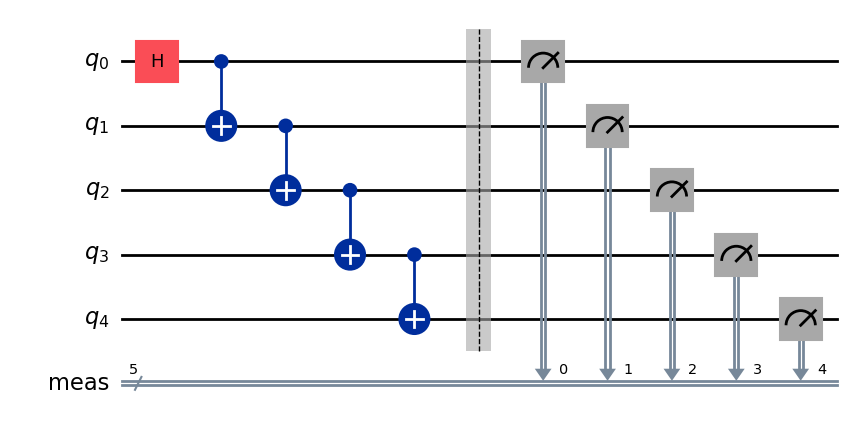

In [32]:
# Draw colored circuit diagram
qc.draw(output='mpl')

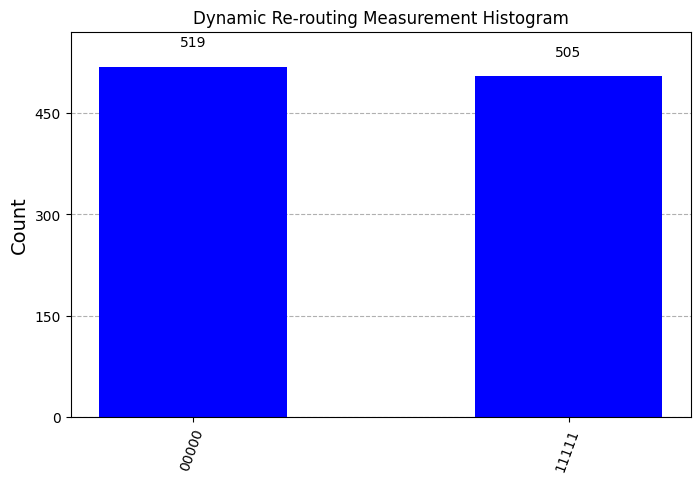

In [127]:
# Display a colored measurement histogram (using a single color for clarity).
plot_histogram(counts, color='blue', title="Dynamic Re-routing Measurement Histogram", figsize=(8,5))

In [55]:

qc_layout = QuantumCircuit(5)
qc_layout.h(0)
qc_layout.cx(0, 1)
qc_layout.cx(1, 2)
qc_layout.cx(2, 3)
qc_layout.cx(3, 4)
qc_layout.measure_all()

# Create an initial layout mapping: map each circuit qubit to the corresponding physical qubit.
initial_layout = {qc_layout.qubits[i]: i for i in range(qc_layout.num_qubits)}

optimized_layout = transpile(qc_layout,
                             backend=Aer.get_backend('qasm_simulator'),
                             initial_layout=initial_layout,
                             optimization_level=2)




job = Aer.get_backend('qasm_simulator').run(optimized_layout, shots=1024)
counts_layout = job.result().get_counts()




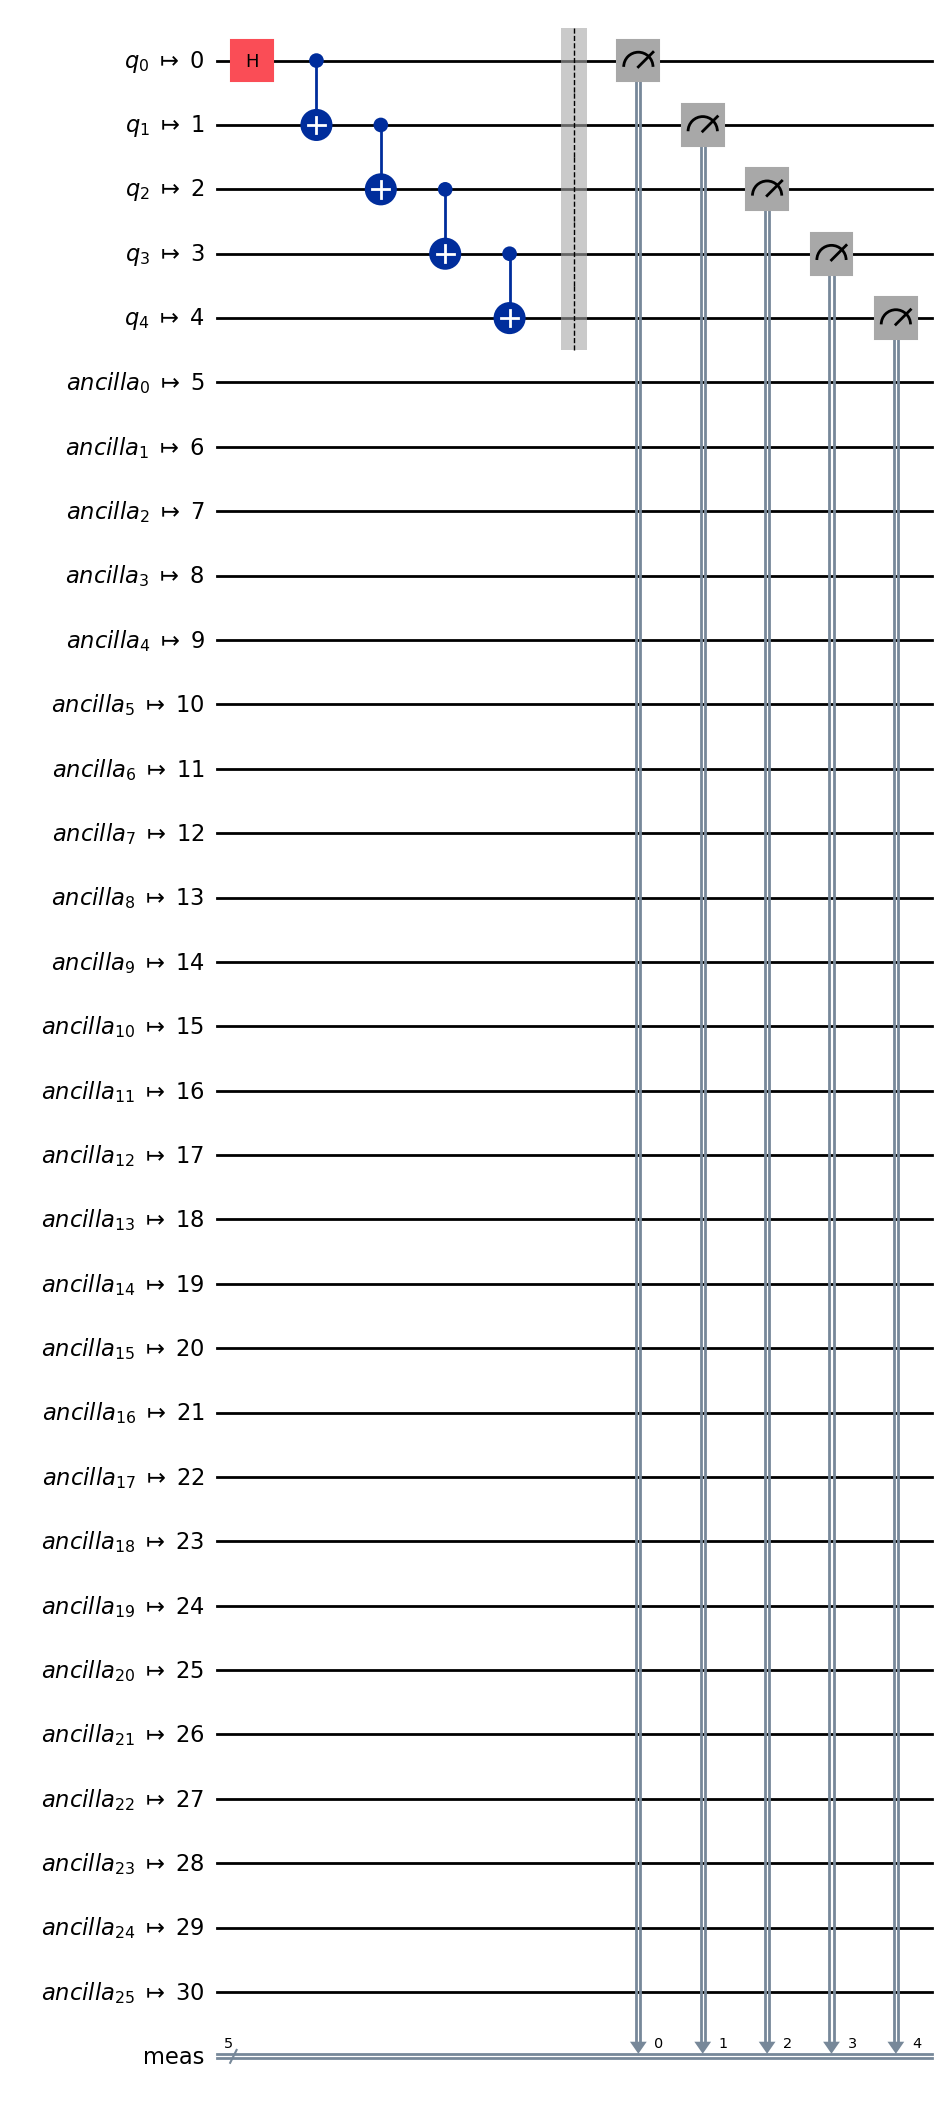

In [56]:
optimized_layout.draw(output='mpl')

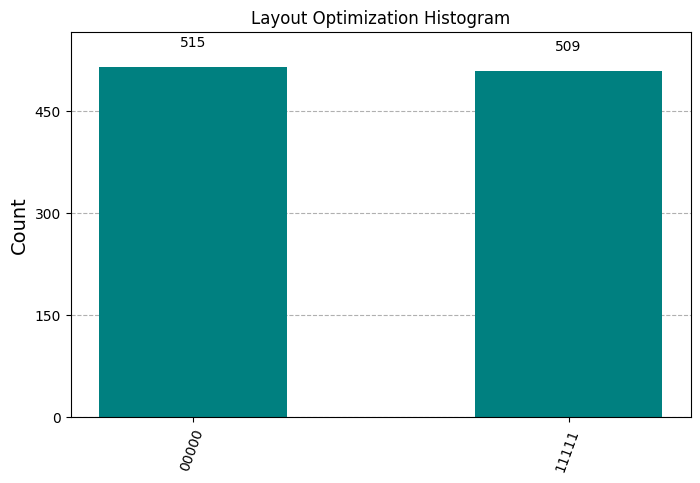

In [38]:
plot_histogram(counts_layout, color='teal', title="Layout Optimization Histogram", figsize=(8,5))

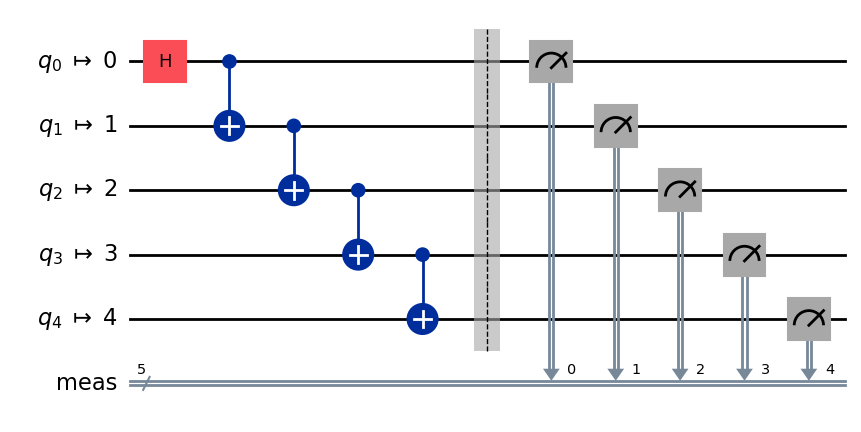

In [39]:
qc_connect = QuantumCircuit(5)
qc_connect.h(0)
qc_connect.cx(0, 1)
qc_connect.cx(1, 2)
qc_connect.cx(2, 3)
qc_connect.cx(3, 4)
qc_connect.measure_all()

# Define a coupling map for linear connectivity: 0-1-2-3-4.
coupling_map = [[0, 1], [1, 0],
                [1, 2], [2, 1],
                [2, 3], [3, 2],
                [3, 4], [4, 3]]

optimized_connect = transpile(qc_connect,
                              backend=Aer.get_backend('qasm_simulator'),
                              coupling_map=coupling_map,
                              optimization_level=2)

optimized_connect.draw(output='mpl')


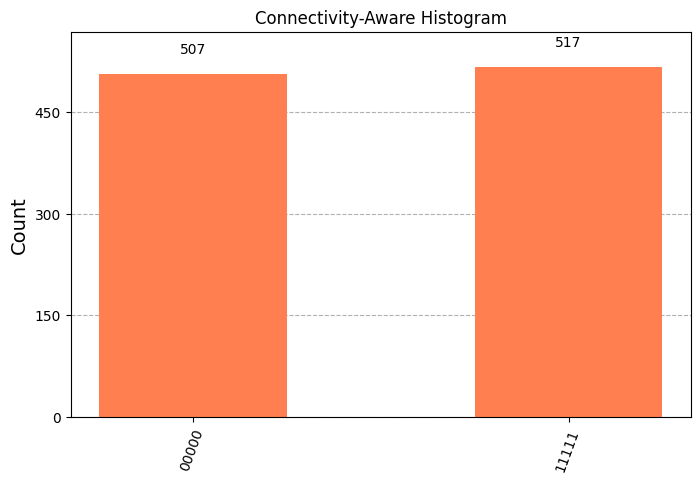

In [40]:
job = Aer.get_backend('qasm_simulator').run(optimized_connect, shots=1024)
counts_connect = job.result().get_counts()
plot_histogram(counts_connect, color='coral', title="Connectivity-Aware Histogram", figsize=(8,5))


In [64]:


# Build a baseline 5-qubit circuit.
qc = QuantumCircuit(5)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.cx(2, 3)
qc.cx(3, 4)
qc.measure_all()

# Set backend.
backend = Aer.get_backend('qasm_simulator')

# ------------------------------
# Baseline (no error mitigation)
qc_baseline = transpile(qc, backend=backend)
job_baseline = backend.run(qc_baseline, shots=1024)
counts_baseline = job_baseline.result().get_counts()

# ------------------------------
# 1. Dynamic Circuit Re-routing using SABRE routing.
qc_reroute = transpile(qc, backend=backend, routing_method='sabre', optimization_level=2)
job_reroute = backend.run(qc_reroute, shots=1024)
counts_reroute = job_reroute.result().get_counts()

# ------------------------------
# 2. Connectivity-Aware Compilation using a coupling map.
coupling_map = [[0, 1], [1, 0],
                [1, 2], [2, 1],
                [2, 3], [3, 2],
                [3, 4], [4, 3]]
qc_connect = transpile(qc, backend=backend, coupling_map=coupling_map, optimization_level=2)
job_connect = backend.run(qc_connect, shots=1024)
counts_connect = job_connect.result().get_counts()

# ------------------------------
# 3. Qubit Layout Optimization using an explicit initial layout.
initial_layout = {qc.qubits[i]: i for i in range(qc.num_qubits)}
qc_layout = transpile(qc, backend=backend, initial_layout=initial_layout, optimization_level=2)
job_layout = backend.run(qc_layout, shots=1024)
counts_layout = job_layout.result().get_counts()



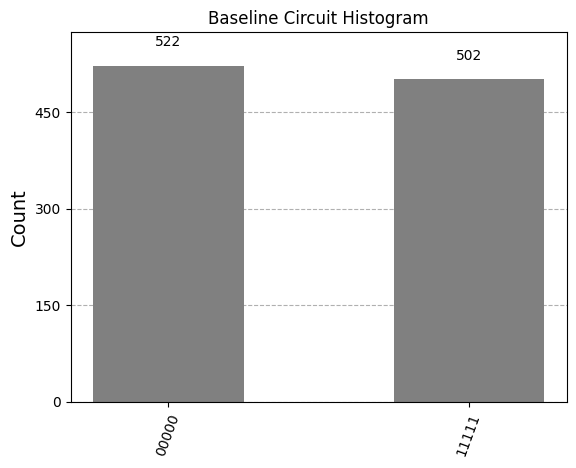

In [65]:
plot_histogram(counts_baseline, color='grey', title="Baseline Circuit Histogram")



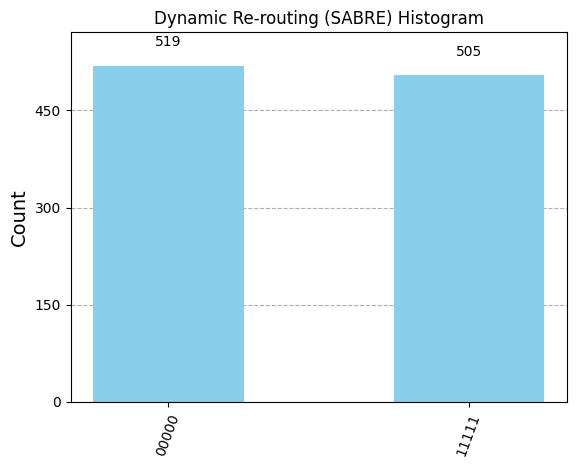

In [66]:
plot_histogram(counts_reroute, color='skyblue', title="Dynamic Re-routing (SABRE) Histogram")


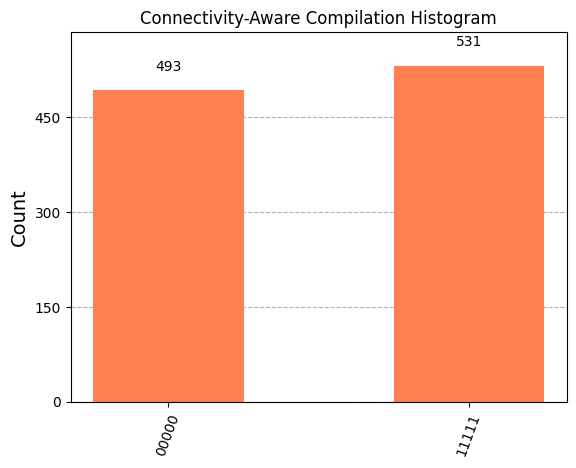

In [67]:
plot_histogram(counts_connect, color='coral', title="Connectivity-Aware Compilation Histogram")


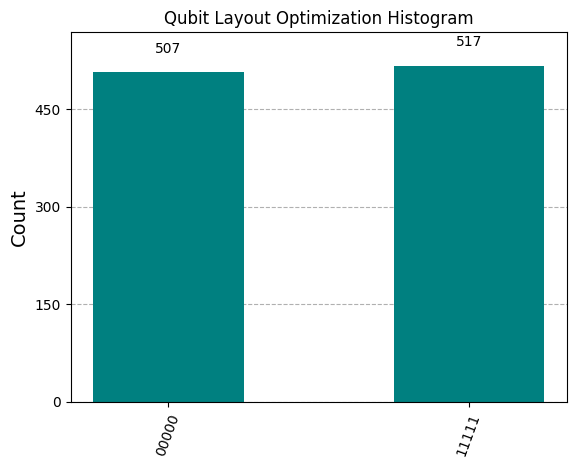

In [68]:
plot_histogram(counts_layout, color='teal', title="Qubit Layout Optimization Histogram")

Decoherence Suppression (ALAP Scheduling)


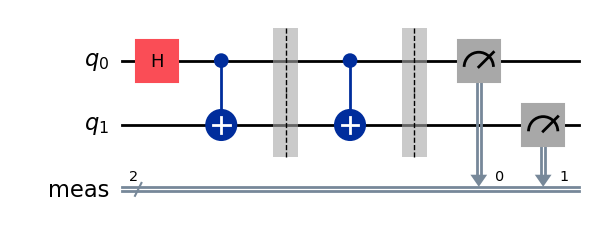

In [84]:
from qiskit import QuantumCircuit, transpile, schedule
from qiskit.visualization.timeline import draw, IQXSimple
from qiskit.providers.fake_provider import GenericBackendV2
import matplotlib.pyplot as plt

# Create a 2-qubit circuit intended to suppress decoherence via optimized scheduling.
qc_decoherence = QuantumCircuit(2)
qc_decoherence.h(0)
qc_decoherence.cx(0, 1)
qc_decoherence.barrier()    # Force separation between operations.
qc_decoherence.cx(0, 1)
qc_decoherence.measure_all()

# Transpile with ALAP scheduling to delay pulses and compress idle time.
qc_decoherence_sched = transpile(qc_decoherence,
                                 backend=GenericBackendV2(5),
                                 scheduling_method='alap',
                                 layout_method='trivial')


print("Decoherence Suppression (ALAP Scheduling)")
qc_decoherence.draw(output='mpl')

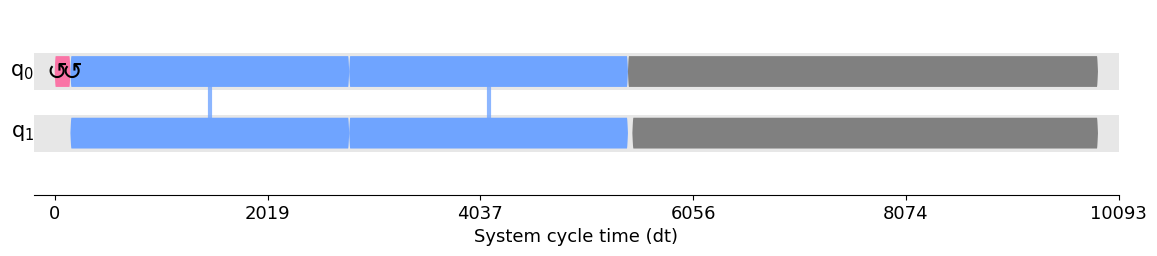

In [73]:
draw(qc_decoherence_sched, style=IQXSimple())

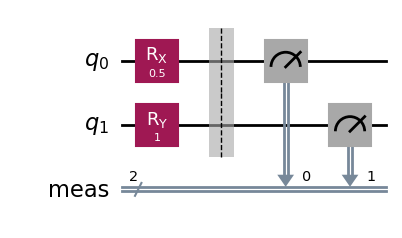

In [86]:
from qiskit import QuantumCircuit, transpile, schedule
from qiskit.visualization.timeline import draw, IQXSimple
from qiskit.providers.fake_provider import GenericBackendV2
import matplotlib.pyplot as plt

# Create a 2-qubit circuit that uses RX and RY gates (conceptually emulating smooth pulse envelopes).
qc_pulse = QuantumCircuit(2)
qc_pulse.rx(0.5, 0)
qc_pulse.ry(1.0, 1)
qc_pulse.measure_all()

# Transpile with ALAP scheduling.
qc_pulse_sched = transpile(qc_pulse,
                           backend=GenericBackendV2(5),
                           scheduling_method='alap',
                           layout_method='trivial')
qc_pulse.draw(output='mpl')


In [87]:
print("Pulse Shaping (Parameterized Rotations)")

Pulse Shaping (Parameterized Rotations)


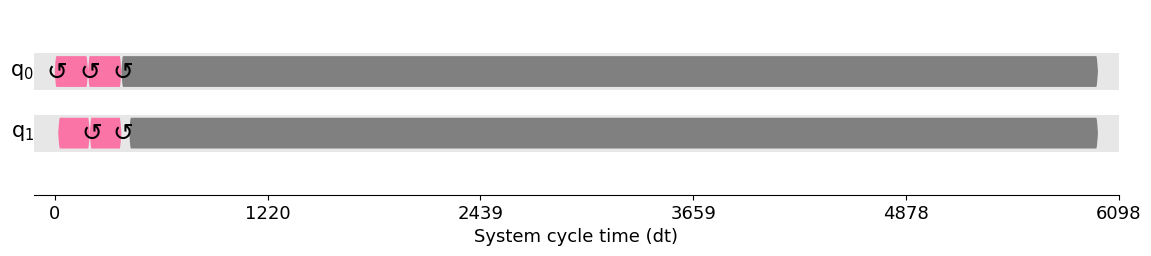

In [75]:
draw(qc_pulse_sched, style=IQXSimple())

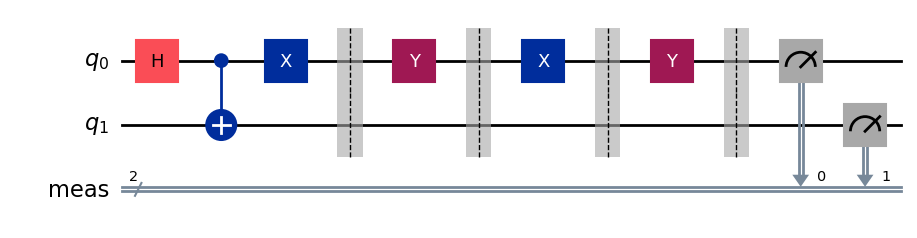

In [89]:
from qiskit import QuantumCircuit, transpile, schedule
from qiskit.visualization.timeline import draw, IQXSimple
from qiskit.providers.fake_provider import GenericBackendV2
import matplotlib.pyplot as plt

# Build a 2-qubit circuit mimicking an XY-4 dynamic decoupling sequence.
qc_dd = QuantumCircuit(2)
qc_dd.h(0)
qc_dd.cx(0, 1)
qc_dd.x(0)          # X pulse
qc_dd.barrier()
qc_dd.y(0)          # Y pulse
qc_dd.barrier()
qc_dd.x(0)          # X pulse
qc_dd.barrier()
qc_dd.y(0)          # Y pulse
qc_dd.measure_all()

# Transpile with ALAP scheduling.
qc_dd_sched = transpile(qc_dd,
                        backend=GenericBackendV2(5),
                        scheduling_method='alap',
                        layout_method='trivial')
qc_dd.draw(output='mpl')



In [90]:
print("Dynamic Decoupling (XY-4 Sequence, ALAP Scheduling)")

Dynamic Decoupling (XY-4 Sequence, ALAP Scheduling)


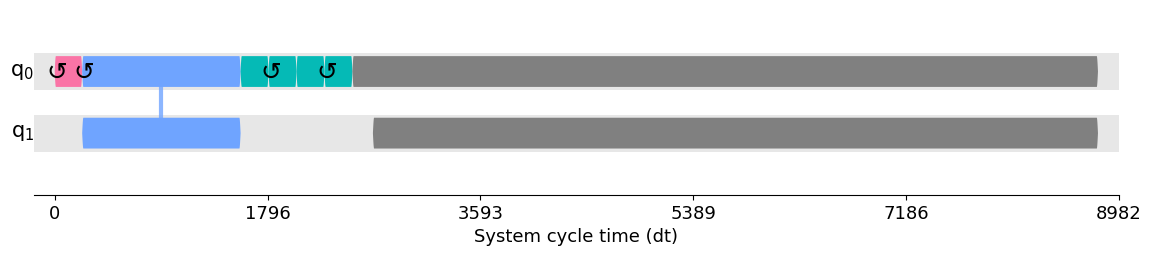

In [79]:
draw(qc_dd_sched, style=IQXSimple())


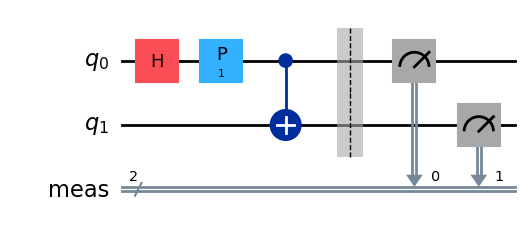

In [91]:
from qiskit import QuantumCircuit, transpile, schedule
from qiskit.visualization.timeline import draw, IQXSimple
from qiskit.providers.fake_provider import GenericBackendV2
import matplotlib.pyplot as plt

# Build a 2-qubit circuit that applies a phase (P) gate to emulate frequency modulation.
qc_freq = QuantumCircuit(2)
qc_freq.h(0)
qc_freq.p(1.0, 0)    # Apply a phase shift to simulate frequency modulation.
qc_freq.cx(0, 1)
qc_freq.measure_all()

# Transpile with ALAP scheduling.
qc_freq_sched = transpile(qc_freq,
                          backend=GenericBackendV2(5),
                          scheduling_method='alap',
                          layout_method='trivial')
qc_freq.draw(output='mpl')





In [92]:
print("Frequency Modulation (ALAP Scheduling)")

Frequency Modulation (ALAP Scheduling)


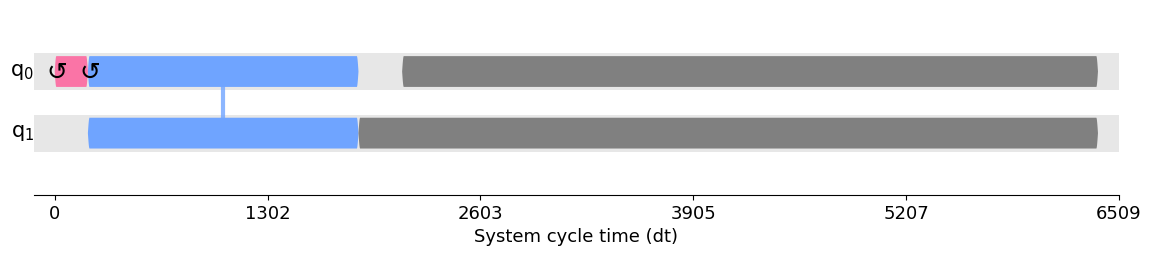

In [81]:
draw(qc_freq_sched, style=IQXSimple())

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.visualization import plot_histogram

# Create a depolarizing error for 1-qubit gates (dummy error rate)
error = depolarizing_error(0.05, 1)
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(error, ['h'])

# Use the Aer qasm_simulator backend.
from qiskit_aer import Aer
backend = Aer.get_backend('qasm_simulator')


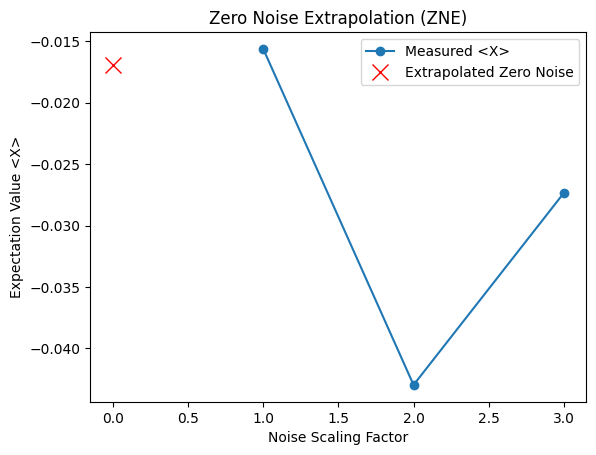

In [98]:
# Build a simple circuit: prepare |+> state and measure in the X basis.
qc_zne = QuantumCircuit(1, 1)
qc_zne.h(0)
qc_zne.measure(0, 0)

scaling_factors = [1, 2, 3]
expectations = []

for s in scaling_factors:
    qc_scaled = qc_zne.copy()
    # Insert (s-1) id gates to add extra noise (identity operations)
    for _ in range(s - 1):
        qc_scaled.id(0)
    # Transpile the circuit
    qc_scaled_t = transpile(qc_scaled, backend=backend)
    job = backend.run(qc_scaled_t, shots=1024, noise_model=noise_model)
    counts = job.result().get_counts()
    p0 = counts.get('0', 0) / 1024
    p1 = counts.get('1', 0) / 1024
    exp_val = p0 - p1  # Expectation value for measurement in the X basis
    expectations.append(exp_val)

# Fit a line and extrapolate to zero noise.
coeffs = np.polyfit(scaling_factors, expectations, 1)
zero_noise = np.polyval(coeffs, 0)

plt.figure()
plt.plot(scaling_factors, expectations, 'o-', label='Measured <X>')
plt.plot(0, zero_noise, 'rx', markersize=12, label='Extrapolated Zero Noise')
plt.xlabel('Noise Scaling Factor')
plt.ylabel('Expectation Value <X>')
plt.title('Zero Noise Extrapolation (ZNE)')
plt.legend()
plt.show()


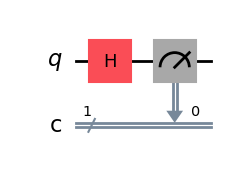

In [104]:
qc_zne.draw(output='mpl')

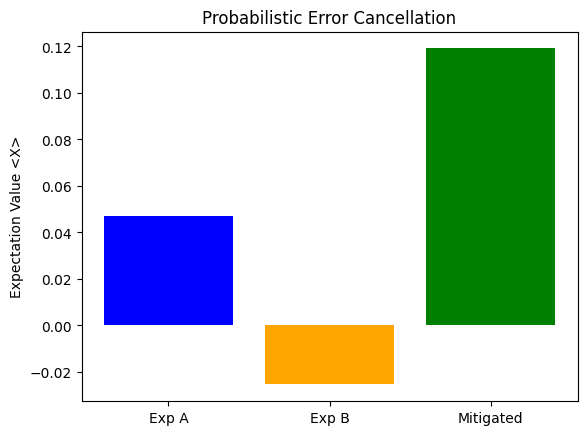

In [132]:
# Circuit A: Base circuit.
qc_A = QuantumCircuit(1, 1)
qc_A.h(0)
qc_A.measure(0, 0)

# Circuit B: Introduce an extra error gate.
qc_B = QuantumCircuit(1, 1)
qc_B.h(0)
qc_B.x(0)  # Extra error gate (perturbation)
qc_B.measure(0, 0)

# Transpile and run Circuit A.
qc_A_t = transpile(qc_A, backend=backend)
job_A = backend.run(qc_A_t, shots=1024, noise_model=noise_model)
counts_A = job_A.result().get_counts()
p0_A = counts_A.get('0', 0) / 1024
exp_A = p0_A - (1 - p0_A)

# Transpile and run Circuit B.
qc_B_t = transpile(qc_B, backend=backend)
job_B = backend.run(qc_B_t, shots=1024, noise_model=noise_model)
counts_B = job_B.result().get_counts()
p0_B = counts_B.get('0', 0) / 1024
exp_B = p0_B - (1 - p0_B)

# Dummy cancellation weights (example values)
alpha = 1.0
beta = -0.5
exp_mitigated = (alpha * exp_A + beta * exp_B) / (alpha + beta)

plt.figure()
plt.bar(['Exp A', 'Exp B', 'Mitigated'], [exp_A, exp_B, exp_mitigated],
        color=['blue', 'orange', 'green'])
plt.ylabel('Expectation Value <X>')
plt.title('Probabilistic Error Cancellation')
plt.show()


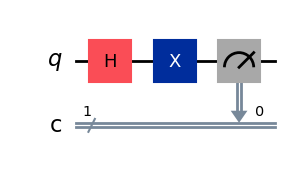

In [130]:
qc_B.draw(output='mpl')

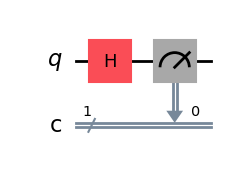

In [131]:
qc_A.draw(output='mpl')

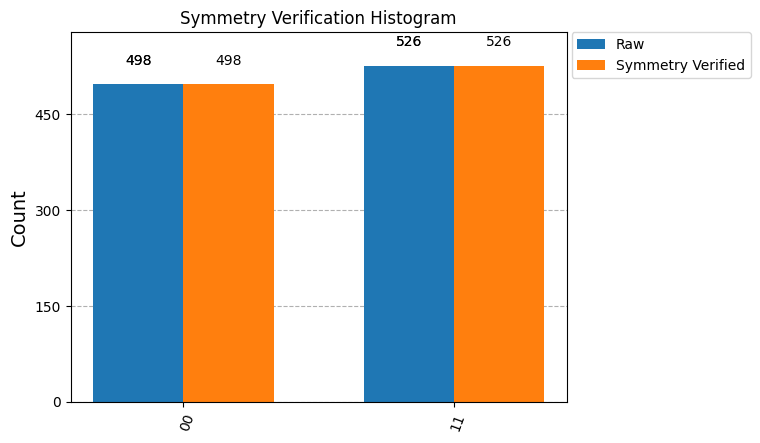

In [101]:
qc_sym = QuantumCircuit(2, 2)
qc_sym.h(0)
qc_sym.cx(0, 1)
qc_sym.measure([0, 1], [0, 1])

qc_sym_t = transpile(qc_sym, backend=backend)
job_sym = backend.run(qc_sym_t, shots=1024, noise_model=noise_model)
counts_sym = job_sym.result().get_counts()

# Filter outcomes with even parity.
counts_sym_filtered = {k: v for k, v in counts_sym.items() if k.count('1') % 2 == 0}

plot_histogram([counts_sym, counts_sym_filtered],
               legend=['Raw', 'Symmetry Verified'],
               title='Symmetry Verification Histogram')


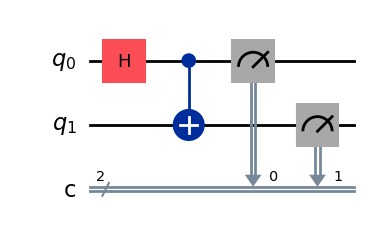

In [108]:
qc_sym.draw(output='mpl')

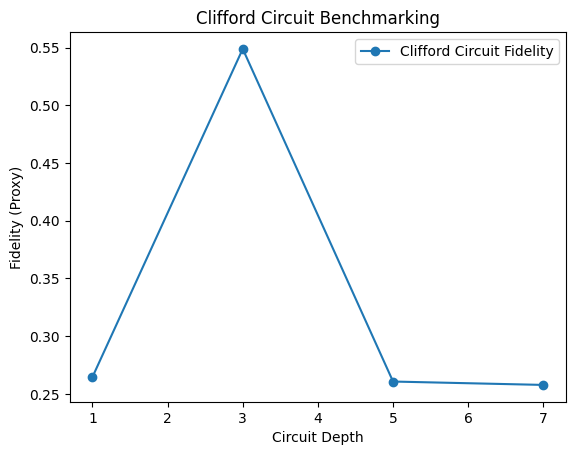

In [102]:
from qiskit.quantum_info import random_clifford
import numpy as np

depths = [1, 3, 5, 7]
fidelities = []

for d in depths:
    qc_cliff = QuantumCircuit(2, 2)
    for _ in range(d):
        cliff = random_clifford(2).to_circuit()
        qc_cliff.compose(cliff, inplace=True)
    qc_cliff.measure_all()
    qc_cliff_t = transpile(qc_cliff, backend=backend)
    job_cliff = backend.run(qc_cliff_t, shots=1024, noise_model=noise_model)
    counts_cliff = job_cliff.result().get_counts()
    p_max = max(counts_cliff.values()) / 1024
    fidelities.append(p_max)

plt.figure()
plt.plot(depths, fidelities, 'o-', label='Clifford Circuit Fidelity')
plt.xlabel('Circuit Depth')
plt.ylabel('Fidelity (Proxy)')
plt.title('Clifford Circuit Benchmarking')
plt.legend()
plt.show()


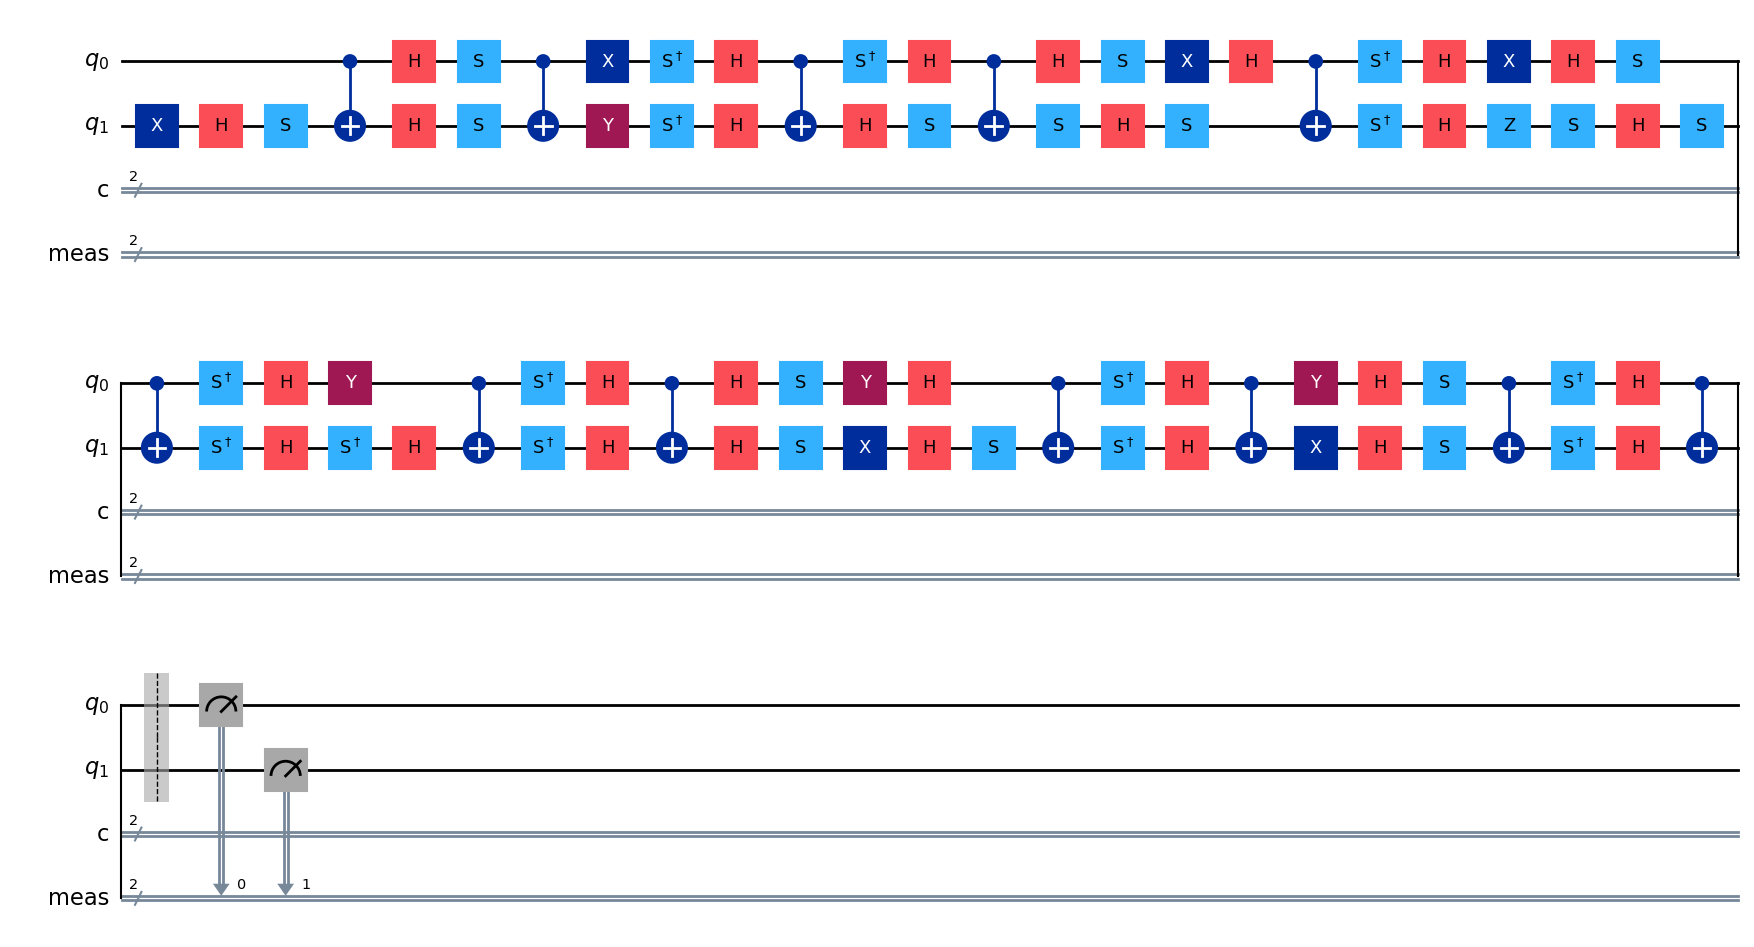

In [109]:
qc_cliff.draw(output='mpl')

In [118]:
def cost_function(theta, noise_model):
    qc_var = QuantumCircuit(1, 1)
    qc_var.ry(theta, 0)
    qc_var.measure(0, 0)
    circuit_draw = qc_var.draw(output='mpl')
    plt.title("Variational Circuit (theta = {:.2f})".format(theta))
    qc_var_t = transpile(qc_var, backend=backend)
    job = backend.run(qc_var_t, shots=1024, noise_model=noise_model)
    counts = job.result().get_counts()
    p0 = counts.get('0', 0) / 1024
    p1 = counts.get('1', 0) / 1024
    exp_val = p0 - p1  # Expectation value of Z (ideal target is 1 for |0>)
    return (1 - exp_val) ** 2,  qc_var


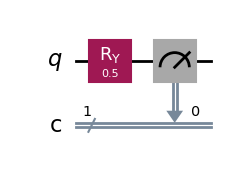

In [124]:
qc_var = QuantumCircuit(1, 1)
qc_var.ry(theta, 0)
qc_var.measure(0, 0)
qc_var.draw(output='mpl')

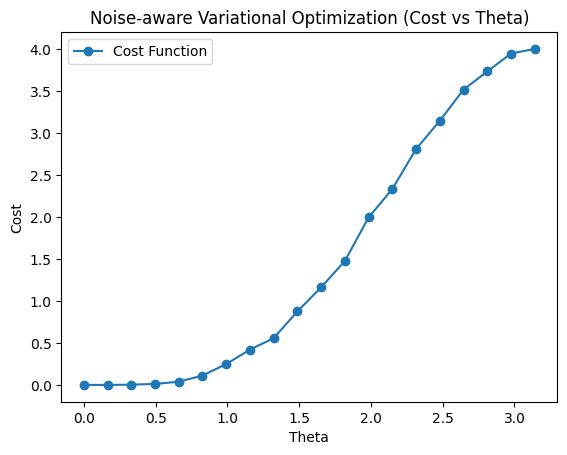

In [113]:

thetas = np.linspace(0, np.pi, 20)
costs = [cost_function(theta, noise_model) for theta in thetas]

plt.figure()
plt.plot(thetas, costs, 'o-', label='Cost Function')
plt.xlabel('Theta')
plt.ylabel('Cost')
plt.title('Noise-aware Variational Optimization (Cost vs Theta)')
plt.legend()
plt.show()

C:\Users\muroo\AppData\Local\Temp\ipykernel_20584\1572360732.py:5: DeprecationWarning: The method ``qiskit.circuit.instructionset.InstructionSet.c_if()`` is deprecated as of qiskit 1.3.0. It will be removed in 2.0.0.
  qc_feedback.x(0).c_if(qc_feedback.cregs[0], 1)


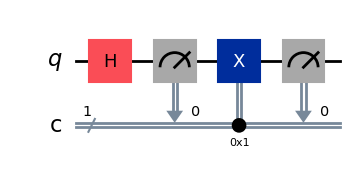

In [9]:
qc_feedback = QuantumCircuit(1, 1)
qc_feedback.h(0)
qc_feedback.measure(0, 0)
# Conditional gate: if the measurement is 1, apply X.
qc_feedback.x(0).c_if(qc_feedback.cregs[0], 1)
# Measure again to verify correction.
qc_feedback.measure(0, 0)

qc_feedback_t = transpile(qc_feedback, backend=backend)
job_feedback = backend.run(qc_feedback_t, shots=1024)
counts_feedback = job_feedback.result().get_counts()


qc_feedback.draw(output='mpl')

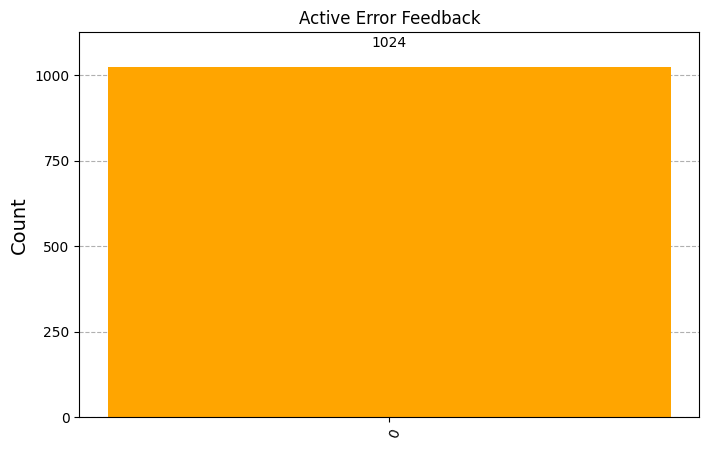

In [135]:
plot_histogram(counts_feedback, title="Active Error Feedback", color='orange', figsize=(8,5))

In [11]:
qc_ft = QuantumCircuit(3, 3)
# Logical |0> encoded as |000> (default initialization)
# Apply a transversal X gate to all physical qubits.
qc_ft.x(0)
qc_ft.x(1)
qc_ft.x(2)
qc_ft.measure(range(3), range(3))
qc_ft_t = transpile(qc_ft, backend=backend)
job_ft = backend.run(qc_ft_t, shots=1024)
counts_ft = job_ft.result().get_counts()


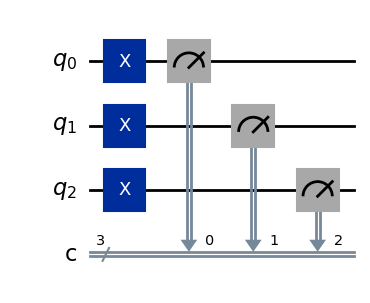

In [12]:
qc_ft.draw(output='mpl')

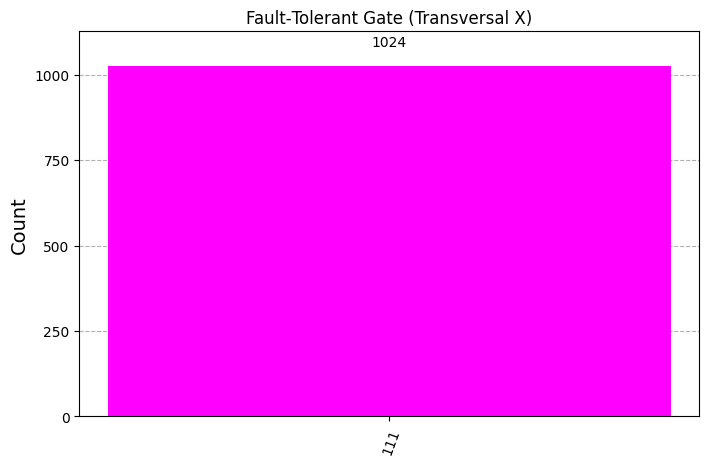

In [140]:

plot_histogram(counts_ft, title="Fault‑Tolerant Gate (Transversal X)", color='magenta', figsize=(8,5))

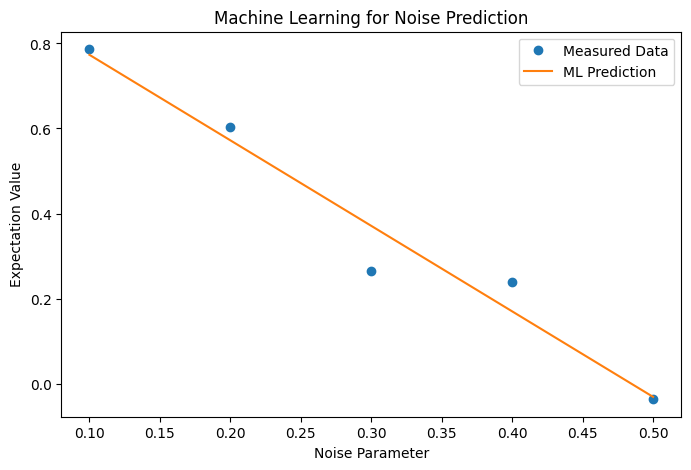

In [141]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Synthetic data: noise parameter vs expectation value.
noise_params = np.array([0.1, 0.2, 0.3, 0.4, 0.5])
# Suppose the ideal expectation is 1, but noise reduces it linearly (plus some noise).
expectations = 1 - 2 * noise_params + np.random.normal(0, 0.05, size=noise_params.shape)

# Fit a linear regression model.
model = LinearRegression()
model.fit(noise_params.reshape(-1, 1), expectations)
noise_range = np.linspace(0.1, 0.5, 100)
pred_expectations = model.predict(noise_range.reshape(-1, 1))

plt.figure(figsize=(8,5))
plt.plot(noise_params, expectations, 'o', label='Measured Data')
plt.plot(noise_range, pred_expectations, '-', label='ML Prediction')
plt.xlabel('Noise Parameter')
plt.ylabel('Expectation Value')
plt.title('Machine Learning for Noise Prediction')
plt.legend()
plt.show()


In [145]:


# Build a 2-qubit circuit that prepares a cat state.
qc_cat = QuantumCircuit(2, 2)
qc_cat.h(0)
qc_cat.cx(0, 1)
qc_cat.barrier()
qc_cat.measure([0, 1], [0, 1])

# Transpile and run on the qasm_simulator.
backend = Aer.get_backend('qasm_simulator')
qc_cat_t = transpile(qc_cat, backend=backend)
job_cat = backend.run(qc_cat_t, shots=1024)
counts_cat = job_cat.result().get_counts()


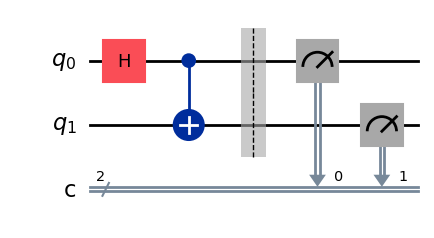

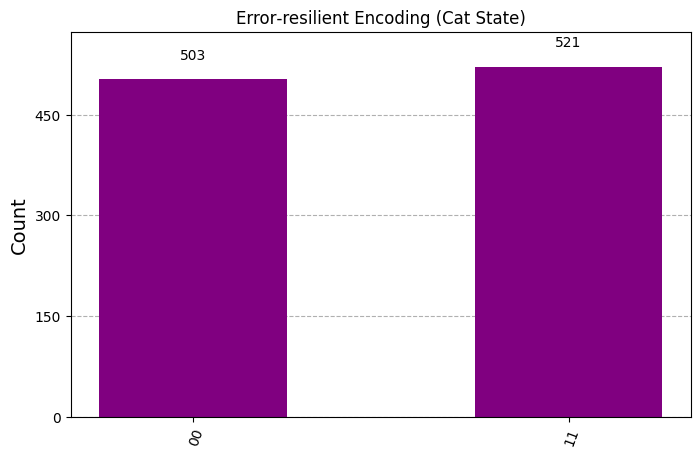

In [144]:

plot_histogram(counts_cat, title="Error‑resilient Encoding (Cat State)", color='purple', figsize=(8,5))


In [150]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram

# Define the backend.
backend = Aer.get_backend('qasm_simulator')

def run_with_noise_scale(scale):
    qc = QuantumCircuit(1, 1)
    qc.h(0)
    qc.measure(0, 0)
    # Insert (scale-1) id gates to amplify noise effects (if noise were present).
    for _ in range(int(scale) - 1):
        qc.id(0)
    qc_t = transpile(qc, backend=backend)
    job = backend.run(qc_t, shots=1024, noise_model=None)  # Replace noise_model=None with an actual noise model to see noise effects.
    return job.result().get_counts()

scales = [1, 2, 3, 4]
for s in scales:
    counts = run_with_noise_scale(s)
    print("Scale", s, "counts:", counts)
    plot_histogram(counts, title=f"Adaptive Noise Filtering (Scale = {s})", color='teal', figsize=(8,5))



Scale 1 counts: {'1': 549, '0': 475}
Scale 2 counts: {'0': 507, '1': 517}
Scale 3 counts: {'0': 523, '1': 501}
Scale 4 counts: {'1': 531, '0': 493}


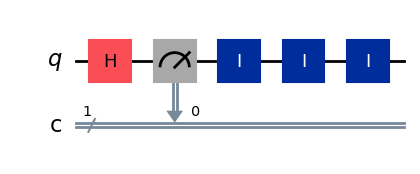

In [13]:
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
# Insert (scale-1) id gates to amplify noise effects (if noise were present).
for _ in range(int(scale) - 1):
    qc.id(0)
qc.draw(output='mpl')

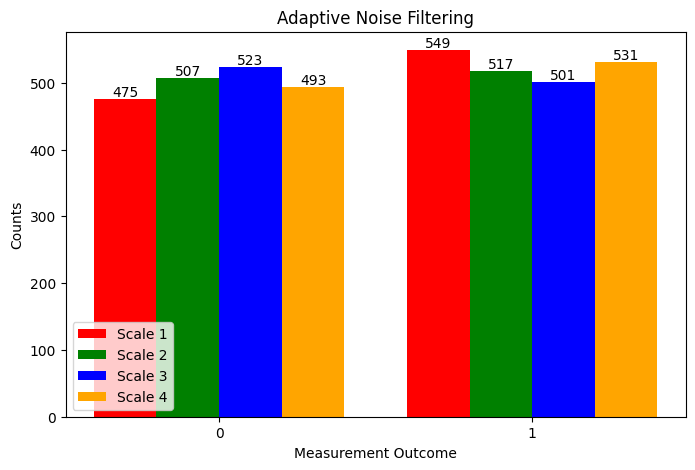

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Given counts for each scale.
counts_data = {
    1: {'1': 549, '0': 475},
    2: {'0': 507, '1': 517},
    3: {'0': 523, '1': 501},
    4: {'1': 531, '0': 493}
}

scales = [1, 2, 3, 4]
outcomes = ['0', '1']

# Set up positions for groups (each group is an outcome).
x = np.arange(len(outcomes))  # positions for outcomes: 0 and 1
width = 0.2  # width for each bar

# Define a color for each scale.
colors = ['red', 'green', 'blue', 'orange']

fig, ax = plt.subplots(figsize=(8, 5))

# Plot each scale's data with an offset and annotate the bars.
for i, scale in enumerate(scales):
    offset = (i - (len(scales) - 1) / 2) * width  # center bars in each group
    values = [counts_data[scale].get(outcome, 0) for outcome in outcomes]
    bars = ax.bar(x + offset, values, width, label=f"Scale {scale}", color=colors[i])
    # Annotate each bar with its count.
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, height, f'{int(height)}',
                ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(outcomes)
ax.set_xlabel("Measurement Outcome")
ax.set_ylabel("Counts")
ax.set_title("Adaptive Noise Filtering")
ax.legend()

plt.show()


In [14]:


# Conceptual 9-qubit surface code circuit.
# (Note: A full surface code requires ancilla qubits for syndrome extraction.
#  Here we prepare a logical state and then measure data qubits as a proxy.)
qc_surface = QuantumCircuit(9, 9)
# Prepare a simple entangled state across 9 qubits.
qc_surface.h(0)
qc_surface.cx(0, 1)
qc_surface.cx(1, 2)
qc_surface.cx(2, 3)
qc_surface.cx(3, 4)
qc_surface.cx(4, 5)
qc_surface.cx(5, 6)
qc_surface.cx(6, 7)
qc_surface.cx(7, 8)
# In a real surface code, ancilla qubits would be interleaved to measure stabilizers.
qc_surface.barrier()
qc_surface.measure(range(9), range(9))

# Draw circuit.


# Simulate and plot histogram.
backend = Aer.get_backend('qasm_simulator')
qc_surface_t = transpile(qc_surface, backend)
job_surface = backend.run(qc_surface_t, shots=1024)
counts_surface = job_surface.result().get_counts()



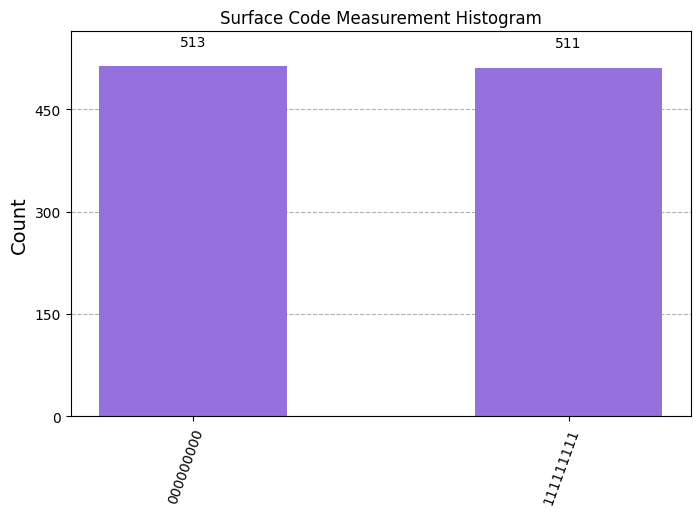

In [15]:
plot_histogram(counts_surface, title="Surface Code Measurement Histogram", color='mediumpurple', figsize=(8,5))

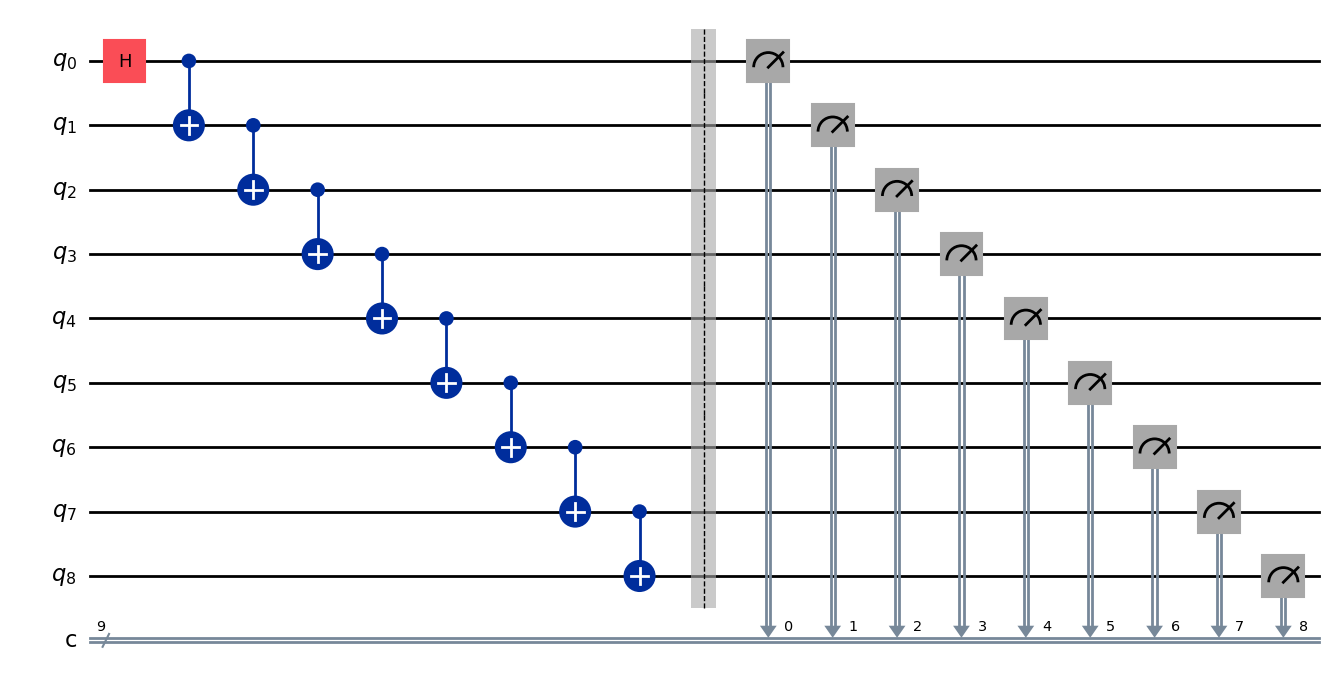

In [16]:
qc_surface.draw(output='mpl')

In [17]:

# Conceptual 9-qubit concatenated code:
# Outer code: 3-qubit repetition code.
# Inner code: Each qubit is further encoded by a 3-qubit repetition.
qc_concat = QuantumCircuit(9, 9)
# For demonstration, we “copy” a logical |0> state redundantly.
# In a 3-qubit repetition code, logical |0> is |000>.
# Here we prepare |0> on qubits 0,1,2 for first block,
# 3,4,5 for second block and 6,7,8 for third block.
# For demonstration, we use barrier to indicate encoding blocks.
qc_concat.barrier([0,1,2])
qc_concat.barrier([3,4,5])
qc_concat.barrier([6,7,8])
# Measure all qubits.
qc_concat.measure(range(9), range(9))



backend = Aer.get_backend('qasm_simulator')
qc_concat_t = transpile(qc_concat, backend)
job_concat = backend.run(qc_concat_t, shots=1024)
counts_concat = job_concat.result().get_counts()



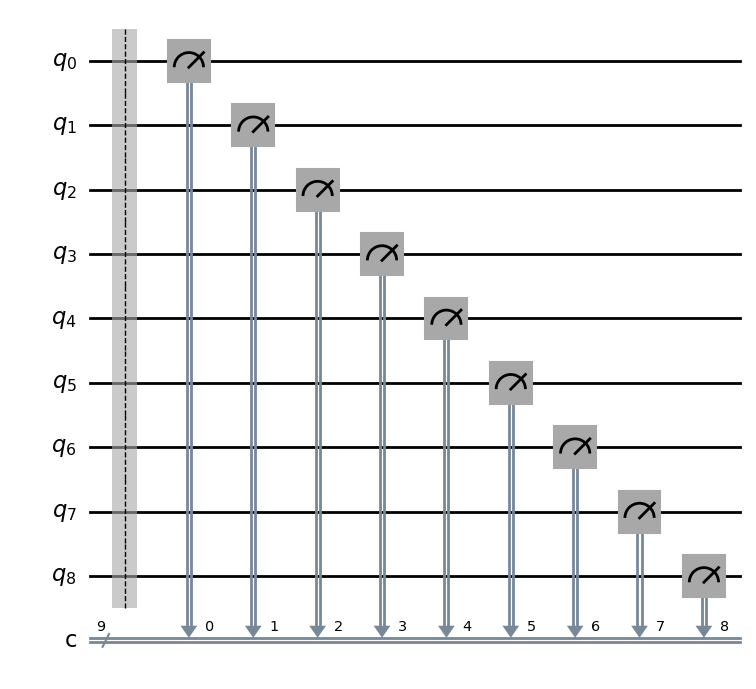

In [18]:
qc_concat.draw(output='mpl')

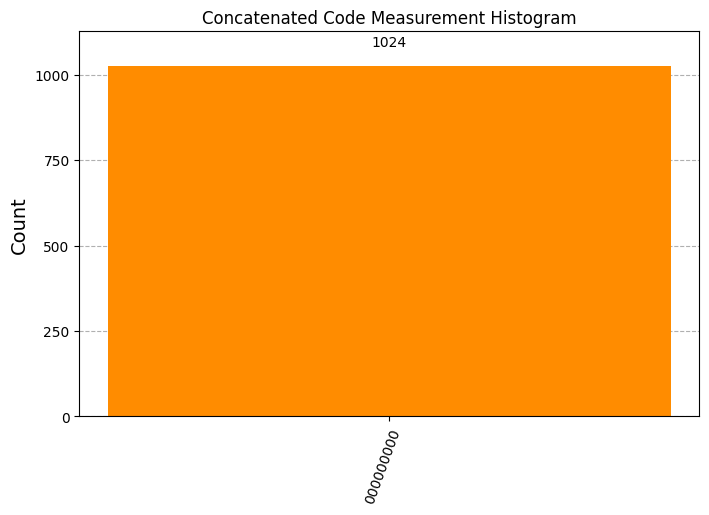

In [19]:
plot_histogram(counts_concat, title="Concatenated Code Measurement Histogram", color='darkorange', figsize=(8,5))

In [22]:


# Conceptual 3-qubit stabilizer code (GHZ state as an example).
qc_stabilizer = QuantumCircuit(3, 3)
qc_stabilizer.h(0)
qc_stabilizer.cx(0, 1)
qc_stabilizer.cx(0, 2)
# The stabilizers here are X⊗X⊗X and Z⊗Z⊗I (etc.). We simulate by measuring all qubits.
qc_stabilizer.measure(range(3), range(3))



backend = Aer.get_backend('qasm_simulator')
qc_stab_t = transpile(qc_stabilizer, backend)
job_stab = backend.run(qc_stab_t, shots=1024)
counts_stab = job_stab.result().get_counts()



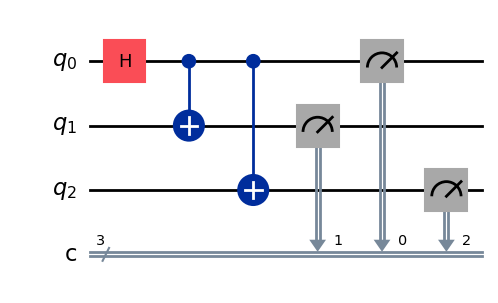

In [23]:
qc_stabilizer.draw(output='mpl')

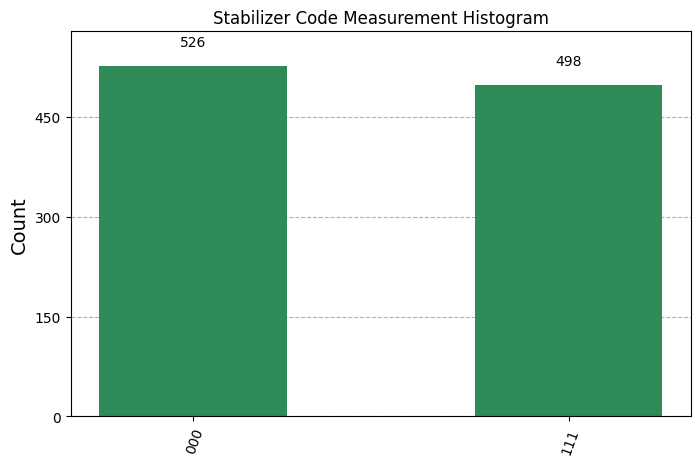

In [24]:
plot_histogram(counts_stab, title="Stabilizer Code Measurement Histogram", color='seagreen', figsize=(8,5))


In [29]:
# Conceptual 9-qubit Shor code.
qc_shor = QuantumCircuit(9, 9)
# Step 1: Encode the logical qubit into a three-qubit bit-flip code.
qc_shor.cx(0, 1)
qc_shor.cx(0, 2)
# Step 2: For each of the three qubits, encode into a phase-flip code (using extra CNOTs).
# Block for qubit 0: use qubits 0,3,6
qc_shor.cx(0, 3)
qc_shor.cx(0, 6)
# Block for qubit 1: use qubits 1,4,7
qc_shor.cx(1, 4)
qc_shor.cx(1, 7)
# Block for qubit 2: use qubits 2,5,8
qc_shor.cx(2, 5)
qc_shor.cx(2, 8)
qc_shor.barrier()
qc_shor.measure(range(9), range(9))


backend = Aer.get_backend('qasm_simulator')
qc_shor_t = transpile(qc_shor, backend)
job_shor = backend.run(qc_shor_t, shots=1024)
counts_shor = job_shor.result().get_counts()



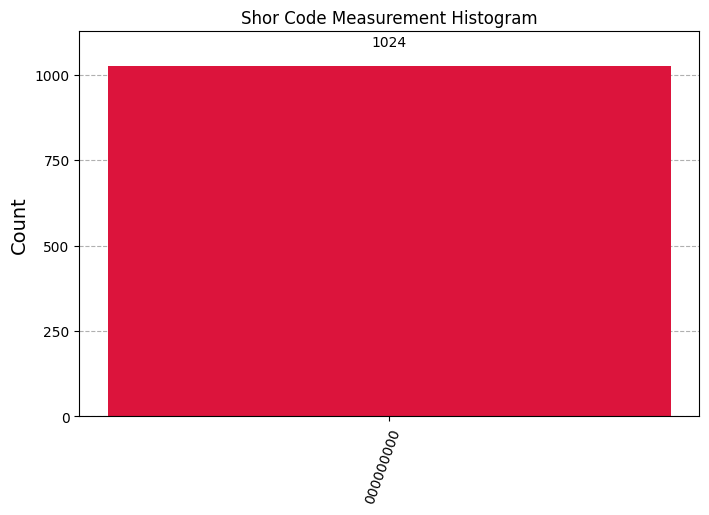

In [30]:
plot_histogram(counts_shor, title="Shor Code Measurement Histogram", color='crimson', figsize=(8,5))

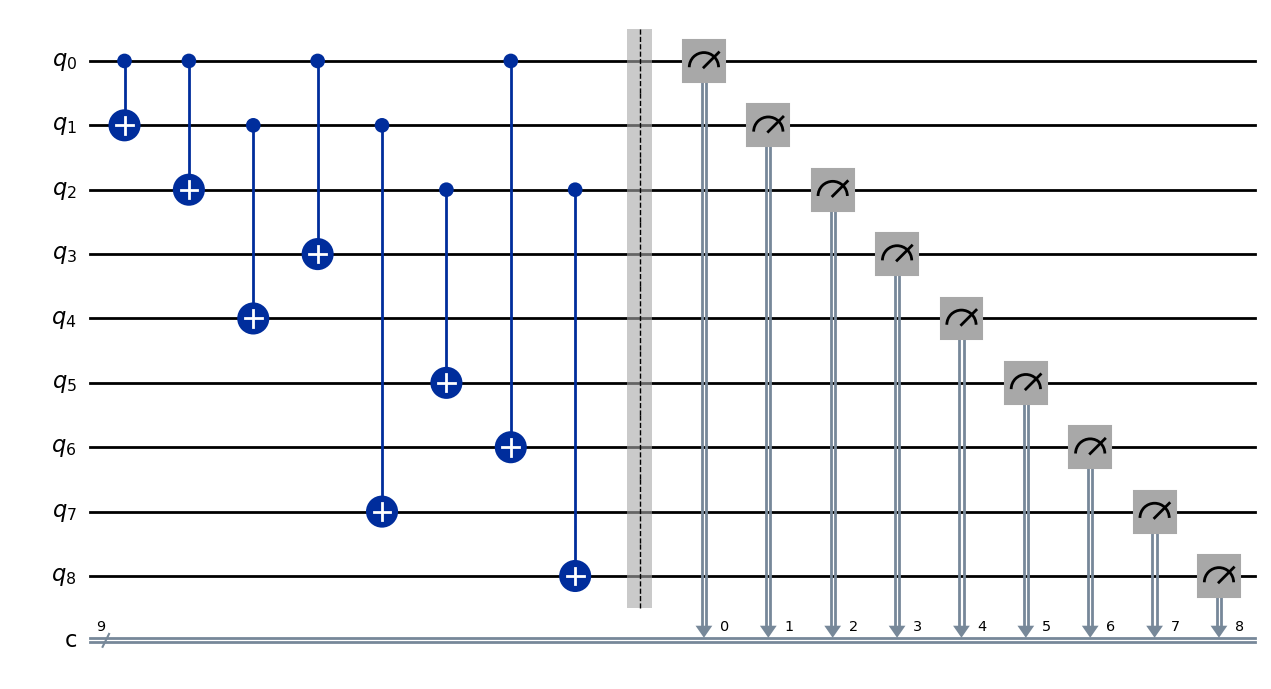

In [31]:
qc_shor.draw(output='mpl')

In [33]:


# Conceptual 7-qubit Steane code.
qc_steane = QuantumCircuit(7, 7)
# Prepare a logical qubit using superposition on qubits 0-2.
qc_steane.h(0)
qc_steane.h(1)
qc_steane.h(2)
# Entangle qubits as per the Hamming(7,4) structure.
qc_steane.cx(0, 3)
qc_steane.cx(1, 3)
qc_steane.cx(0, 4)
qc_steane.cx(2, 4)
qc_steane.cx(1, 5)
qc_steane.cx(2, 5)
qc_steane.cx(0, 6)
qc_steane.cx(1, 6)
qc_steane.cx(2, 6)
qc_steane.barrier()
qc_steane.measure(range(7), range(7))



backend = Aer.get_backend('qasm_simulator')
qc_steane_t = transpile(qc_steane, backend)
job_steane = backend.run(qc_steane_t, shots=1024)
counts_steane = job_steane.result().get_counts()



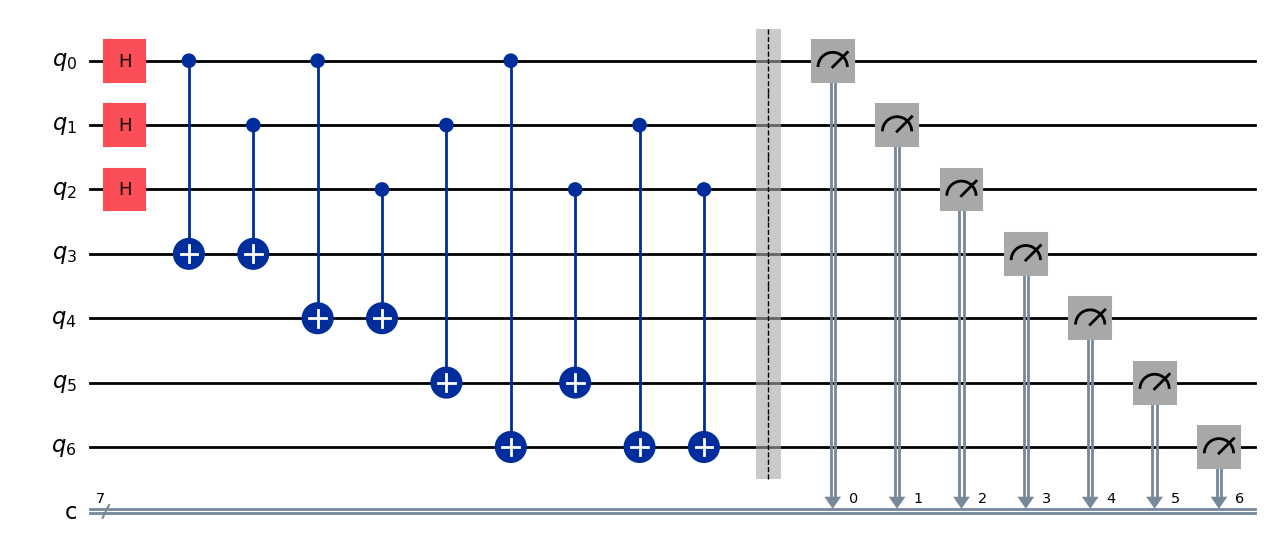

In [34]:
qc_steane.draw(output='mpl')

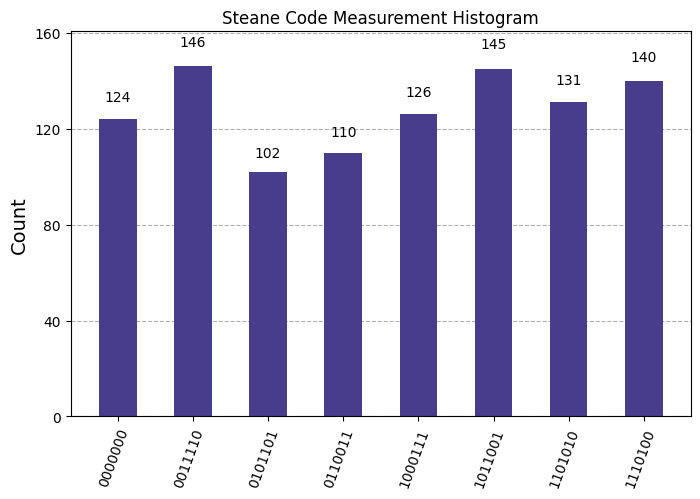

In [35]:
plot_histogram(counts_steane, title="Steane Code Measurement Histogram", color='darkslateblue', figsize=(8,5))

In [37]:
from qiskit.circuit.random import random_circuit

# Create a random 4-qubit circuit (depth 4) to scramble errors.
qc_scramble = random_circuit(4, 4, max_operands=3, seed=42)
qc_scramble.measure_all()

backend = Aer.get_backend('qasm_simulator')
qc_scramble_t = transpile(qc_scramble, backend=backend)
job_scramble = backend.run(qc_scramble_t, shots=1024)
counts_scramble = job_scramble.result().get_counts()





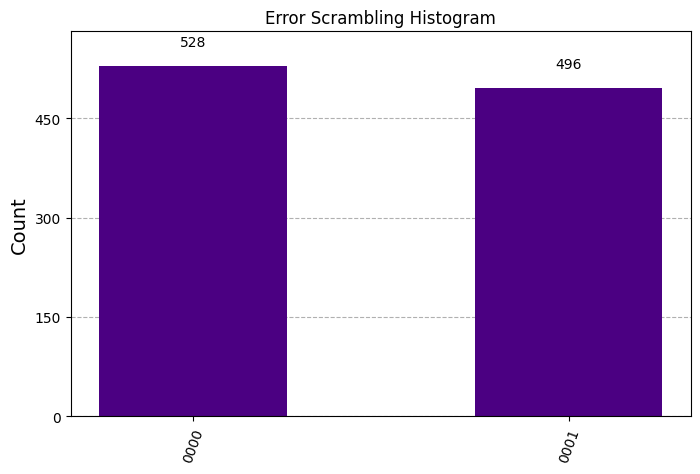

In [38]:

# Plot histogram.
plot_histogram(counts_scramble, title="Error Scrambling Histogram", color='indigo', figsize=(8,5))


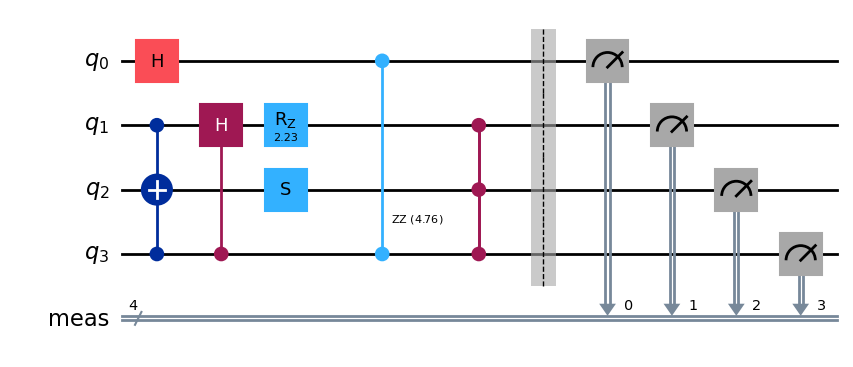

In [39]:
# Draw the circuit.
qc_scramble.draw(output='mpl')


In [40]:
qc_noise = QuantumCircuit(1, 1)
theta = np.pi/4  # Parameter representing the shaped pulse amplitude/angle.
qc_noise.ry(theta, 0)
qc_noise.measure(0, 0)

backend = Aer.get_backend('qasm_simulator')
qc_noise_t = transpile(qc_noise, backend=backend)
job_noise = backend.run(qc_noise_t, shots=1024)
counts_noise = job_noise.result().get_counts()




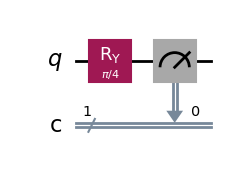

In [41]:
qc_noise.draw(output='mpl')


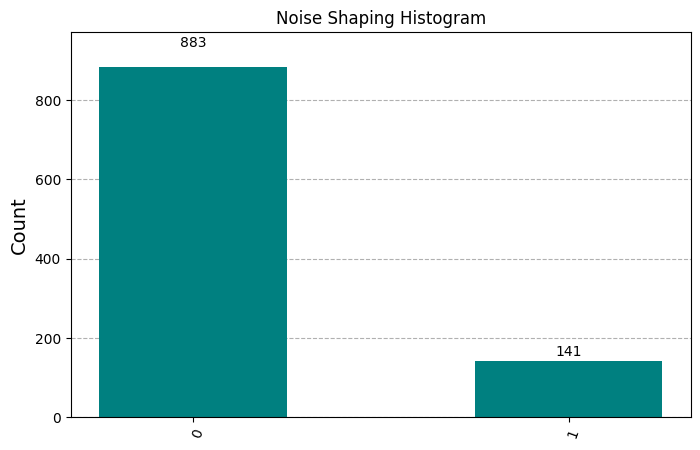

In [42]:

plot_histogram(counts_noise, title="Noise Shaping Histogram", color='teal', figsize=(8,5))


In [43]:


qc_topo = QuantumCircuit(9, 9)
# Prepare an entangled state as a rough surrogate for a topological encoding.
qc_topo.h(0)
qc_topo.cx(0, 1)
qc_topo.cx(1, 2)
qc_topo.cx(2, 3)
qc_topo.cx(3, 4)
qc_topo.cx(4, 5)
qc_topo.cx(5, 6)
qc_topo.cx(6, 7)
qc_topo.cx(7, 8)
qc_topo.barrier()
qc_topo.measure(range(9), range(9))

backend = Aer.get_backend('qasm_simulator')
qc_topo_t = transpile(qc_topo, backend=backend)
job_topo = backend.run(qc_topo_t, shots=1024)
counts_topo = job_topo.result().get_counts()



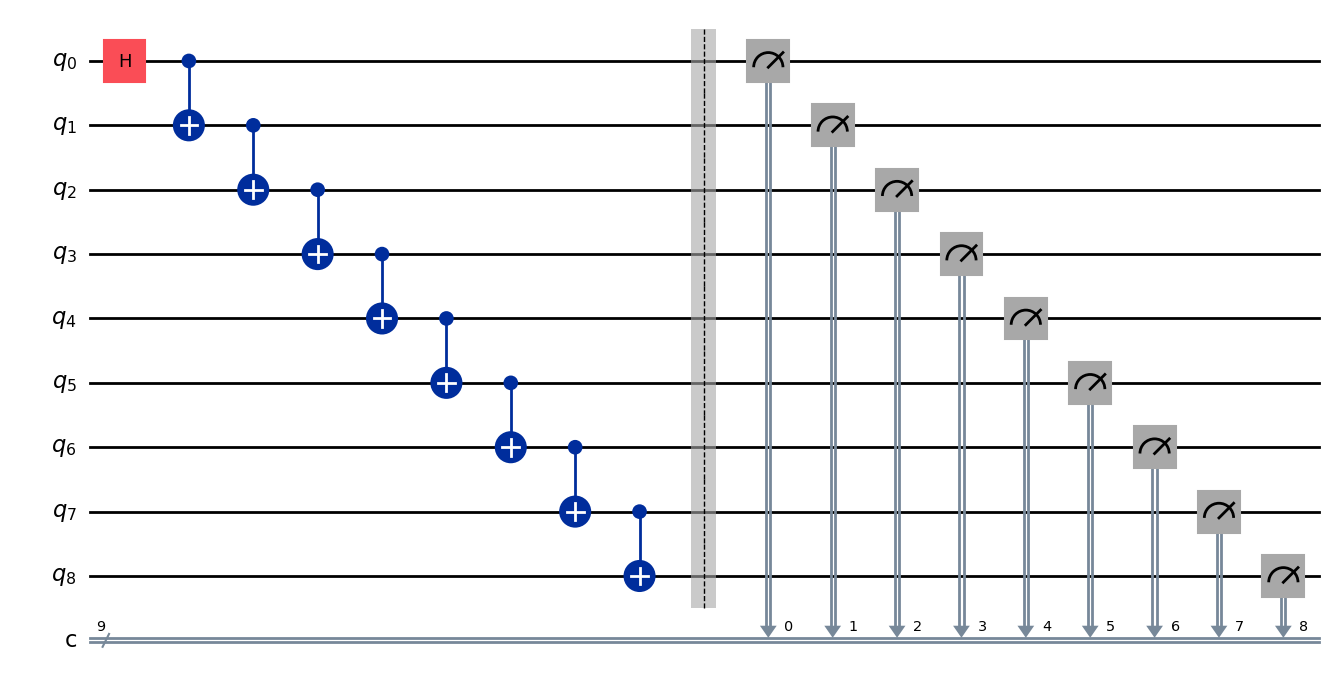

In [44]:
qc_topo.draw(output='mpl')


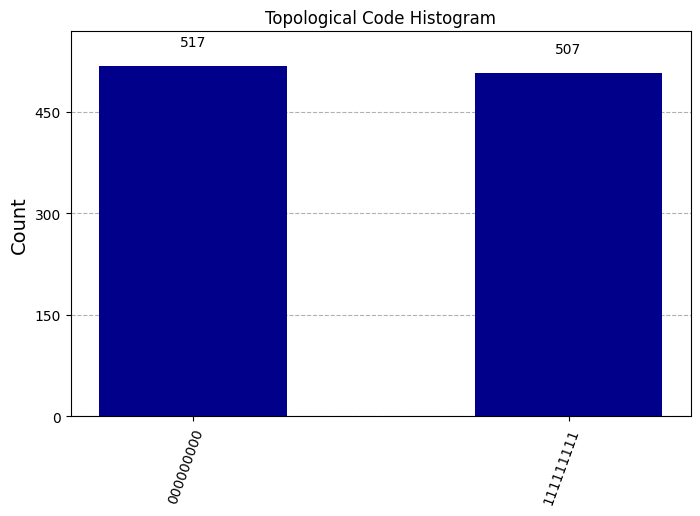

In [45]:
plot_histogram(counts_topo, title="Topological Code Histogram", color='darkblue', figsize=(8,5))

In [49]:


qc_rep = QuantumCircuit(3, 3)
# Logical |0> encoded as |000>.
# For demonstration, we apply a transversal X gate to simulate a logical operation.
qc_rep.x(0)
qc_rep.x(1)
qc_rep.x(2)
qc_rep.measure(range(3), range(3))

backend = Aer.get_backend('qasm_simulator')
qc_rep_t = transpile(qc_rep, backend=backend)
job_rep = backend.run(qc_rep_t, shots=1024)
counts_rep = job_rep.result().get_counts()




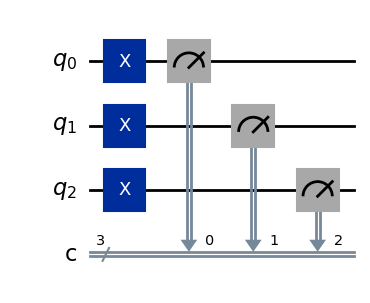

In [50]:
qc_rep.draw(output='mpl')



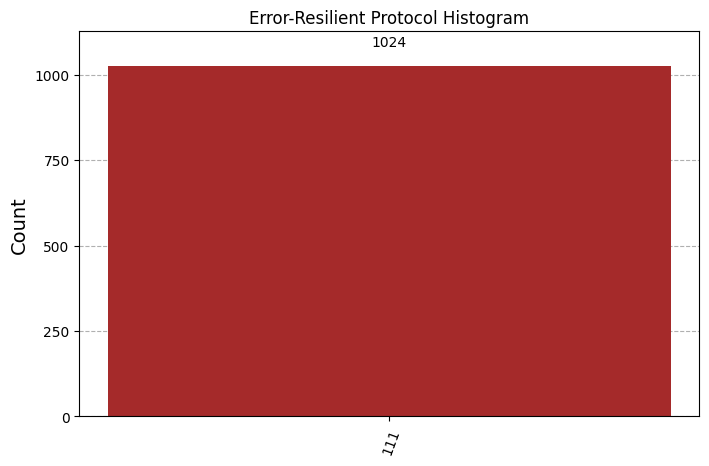

In [51]:
plot_histogram(counts_rep, title="Error-Resilient Protocol Histogram", color='brown', figsize=(8,5))


In [52]:


qc_shield = QuantumCircuit(1, 1)
qc_shield.h(0)
# Insert dynamic decoupling pulses (here, two X pulses separated by barriers) to "shield" the qubit.
qc_shield.barrier()
qc_shield.x(0)
qc_shield.barrier()
qc_shield.x(0)
qc_shield.barrier()
qc_shield.measure(0, 0)

backend = Aer.get_backend('qasm_simulator')
qc_shield_t = transpile(qc_shield, backend=backend)
job_shield = backend.run(qc_shield_t, shots=1024)
counts_shield = job_shield.result().get_counts()




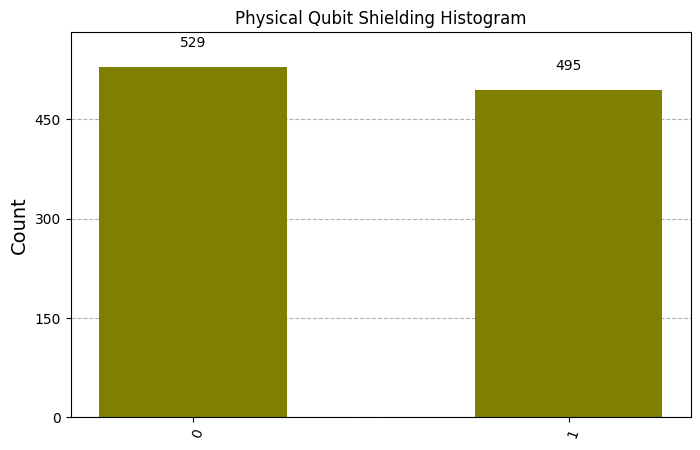

In [53]:
plot_histogram(counts_shield, title="Physical Qubit Shielding Histogram", color='olive', figsize=(8,5))


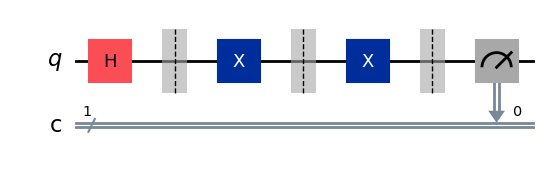

In [54]:
qc_shield.draw(output='mpl')
